# Neural Network 3L (one hidden layer)

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score, mean_squared_error
import itertools

print("PyTorch Version:", torch.__version__)

PyTorch Version: 2.13.0+cpu


## Data Loading and Preprocessing

In [2]:
# load the data
datasets_raw = {
    "Airfoil":  pd.read_csv("../data/airfoil.csv"),
    "Auto MPG": pd.read_csv("../data/auto_mpg.csv"),
    "Concrete": pd.read_csv("../data/concrete.csv"),
}

# target column for each dataset
targets = {
    "Airfoil":  "scaled_sound_pressure_db",
    "Auto MPG": "mpg",
    "Concrete": "compressive_strength_mpa",
}

for name, df in datasets_raw.items():
    print(f"{name}: shape={df.shape}, missing values={df.isnull().sum().sum()}")

Airfoil: shape=(1503, 6), missing values=0
Auto MPG: shape=(392, 8), missing values=0
Concrete: shape=(1030, 9), missing values=0


In [3]:
# 80/20 split
# scaling happens later after the split
splits = {}
for name, df in datasets_raw.items():
    X = df.drop(columns=[targets[name]])
    y = df[targets[name]]
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42
    )
    splits[name] = (X_train, X_test, y_train, y_test)
    print(f"{name}: train={X_train.shape}, test={X_test.shape}")

Airfoil: train=(1202, 5), test=(301, 5)
Auto MPG: train=(313, 7), test=(79, 7)
Concrete: train=(824, 8), test=(206, 8)


## Neural Network Setup

In [4]:
# activations to try
activations = {
    "relu": nn.ReLU,
    "tanh": nn.Tanh,
    "sigmoid": nn.Sigmoid,
}

# 3L net: input -> hidden -> output
class NeuralNet3L(nn.Module):
    def __init__(self, input_size, hidden_size, activation_name):
        super().__init__()
        self.hidden = nn.Linear(input_size, hidden_size) # input -> hidden layer
        self.act = activations[activation_name]()        # hidden layer activation function
        self.output = nn.Linear(hidden_size, 1)          # hidden -> output layer

    def forward(self, x):
        return self.output(self.act(self.hidden(x)))

In [5]:
# converts to tensors
def to_tensors(X, y):
    X_t = torch.tensor(X, dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y), dtype=torch.float32).reshape(-1, 1)  # make y a column
    return X_t, y_t

## Hyperparameter Tuning

In [6]:
# hyperparameter grid
learning_rates = [0.01, 0.05, 0.1]
batch_sizes = [16, 32, 64]
hidden_sizes = [4, 8, 16, 32]
activation_names = ["relu", "tanh", "sigmoid"]
max_epochs = 100
patience = 10   # early stopping

In [7]:
# tuning only uses the training data so the test set stays untouched
def hyperparameter_tuning(X_train_raw, y_train_raw):

    # split train again for validation
    X_tr, X_val, y_tr, y_val = train_test_split(
        X_train_raw, y_train_raw, test_size=0.20, random_state=42
    )

    # scale using just the tuning train part
    scaler = StandardScaler()
    X_tr = scaler.fit_transform(X_tr)
    X_val = scaler.transform(X_val)

    X_tr_t, y_tr_t = to_tensors(X_tr, y_tr)
    X_val_t, y_val_t = to_tensors(X_val, y_val)

    results = []
    best_params = None
    best_history = None
    best_mse = float("inf")

    # try every combo
    combos = itertools.product(hidden_sizes, activation_names, learning_rates, batch_sizes)
    for hidden, act, lr, batch_size in combos:

        torch.manual_seed(42)
        model = NeuralNet3L(X_tr_t.shape[1], hidden, act)
        criterion = nn.MSELoss()
        optimizer = optim.Adam(model.parameters(), lr=lr)

        loader = DataLoader(
            TensorDataset(X_tr_t, y_tr_t),
            batch_size=batch_size,
            shuffle=True
        )

        train_losses, val_losses = [], []
        best_val_mse = float("inf")
        best_epoch = 0
        wait = 0

        for epoch in range(max_epochs):
            model.train()

            # one epoch
            for X_batch, y_batch in loader:
                optimizer.zero_grad()
                loss = criterion(model(X_batch), y_batch)
                loss.backward()
                optimizer.step()

            # check train/val mse
            model.eval()
            with torch.no_grad():
                train_mse = criterion(model(X_tr_t), y_tr_t).item()
                val_mse = criterion(model(X_val_t), y_val_t).item()
            train_losses.append(train_mse)
            val_losses.append(val_mse)

            if val_mse < best_val_mse:
                best_val_mse = val_mse
                best_epoch = epoch + 1
                wait = 0
            else:
                wait += 1
            if wait >= patience:
                break

        current = {
            "hidden_size": hidden,
            "activation": act,
            "learning_rate": lr,
            "batch_size": batch_size,
            "val_mse": best_val_mse,
            "best_epoch": best_epoch,
        }
        results.append(current)
        print(f"hidden={hidden}, act={act}, lr={lr}, batch={batch_size} -> val MSE={best_val_mse:.4f}", flush=True)

        # save the best one
        if best_val_mse < best_mse:
            best_mse = best_val_mse
            best_params = current
            best_history = {"train": train_losses, "val": val_losses}

    print("\nBest Hyperparameters:", best_params)
    return best_params, results, best_history

In [8]:
# run tuning on each dataset (takes a while)
best_params, tuning_results, histories = {}, {}, {}

for name in splits:
    print(f"\n==================== Tuning {name} ====================")
    X_train_raw, _, y_train_raw, _ = splits[name]
    best_params[name], tuning_results[name], histories[name] = hyperparameter_tuning(X_train_raw, y_train_raw)


==================== Tuning Airfoil ====================
hidden=4, act=relu, lr=0.01, batch=16 -> val MSE=31.4635
hidden=4, act=relu, lr=0.01, batch=32 -> val MSE=32.3369
hidden=4, act=relu, lr=0.01, batch=64 -> val MSE=50.0978
hidden=4, act=relu, lr=0.05, batch=16 -> val MSE=32.2721
hidden=4, act=relu, lr=0.05, batch=32 -> val MSE=31.5716
hidden=4, act=relu, lr=0.05, batch=64 -> val MSE=32.6100
hidden=4, act=relu, lr=0.1, batch=16 -> val MSE=31.3880
hidden=4, act=relu, lr=0.1, batch=32 -> val MSE=31.2644
hidden=4, act=relu, lr=0.1, batch=64 -> val MSE=31.2013
hidden=4, act=tanh, lr=0.01, batch=16 -> val MSE=40.1397
hidden=4, act=tanh, lr=0.01, batch=32 -> val MSE=257.5905
hidden=4, act=tanh, lr=0.01, batch=64 -> val MSE=2837.1990
hidden=4, act=tanh, lr=0.05, batch=16 -> val MSE=28.6836
hidden=4, act=tanh, lr=0.05, batch=32 -> val MSE=31.8572
hidden=4, act=tanh, lr=0.05, batch=64 -> val MSE=42.6643
hidden=4, act=tanh, lr=0.1, batch=16 -> val MSE=48.8825
hidden=4, act=tanh, lr=0.1, bat

In [9]:
# best params per dataset
pd.DataFrame(best_params).T

,hidden_size,activation,learning_rate,batch_size,val_mse,best_epoch
Airfoil,32,sigmoid,0.1,16,10.466334,69
Auto MPG,8,sigmoid,0.05,32,5.676745,87
Concrete,32,tanh,0.1,64,23.346127,64


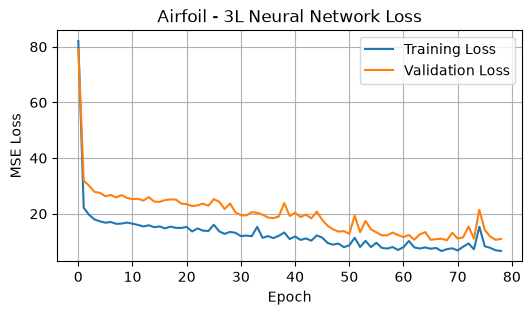

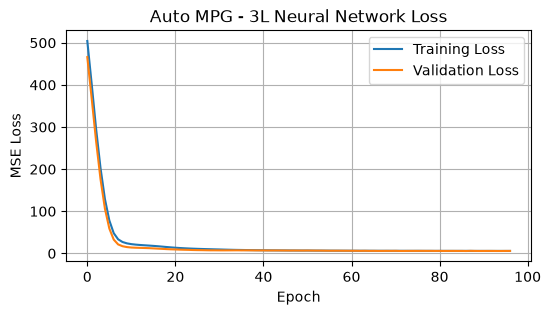

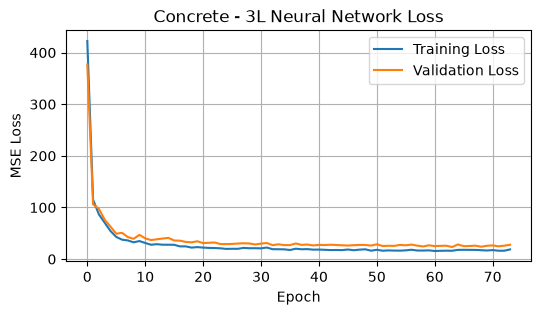

In [10]:
# loss curves for the best params
def plot_loss(history, dataset_name):
    plt.figure(figsize=(6, 3))
    plt.plot(history["train"], label="Training Loss")
    plt.plot(history["val"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("MSE Loss")
    plt.title(f"{dataset_name} - 3L Neural Network Loss")
    plt.legend()
    plt.grid(True)
    plt.show()

for name in histories:
    plot_loss(histories[name], name)

## Model Training

In [11]:
# retrain on the full training set with the best params
def train_final_model(X_train, y_train, params):
    torch.manual_seed(42)
    model = NeuralNet3L(X_train.shape[1], params["hidden_size"], params["activation"])
    criterion = nn.MSELoss()
    optimizer = optim.Adam(model.parameters(), lr=params["learning_rate"])

    loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=params["batch_size"],
        shuffle=True
    )

    model.train()
    for epoch in range(params["best_epoch"]):   # epochs from early stopping
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = criterion(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
    return model

models, tensors = {}, {}

for name, (X_train, X_test, y_train, y_test) in splits.items():
    # fit scaler on train only
    scaler = StandardScaler()
    X_train_s = scaler.fit_transform(X_train)
    X_test_s = scaler.transform(X_test)

    X_train_t, y_train_t = to_tensors(X_train_s, y_train)
    X_test_t, y_test_t = to_tensors(X_test_s, y_test)
    tensors[name] = (X_train_t, y_train_t, X_test_t, y_test_t)

    models[name] = train_final_model(X_train_t, y_train_t, best_params[name])
    print(f"{name}:", models[name])

Airfoil: NeuralNet3L(
  (hidden): Linear(in_features=5, out_features=32, bias=True)
  (act): Sigmoid()
  (output): Linear(in_features=32, out_features=1, bias=True)
)
Auto MPG: NeuralNet3L(
  (hidden): Linear(in_features=7, out_features=8, bias=True)
  (act): Sigmoid()
  (output): Linear(in_features=8, out_features=1, bias=True)
)
Concrete: NeuralNet3L(
  (hidden): Linear(in_features=8, out_features=32, bias=True)
  (act): Tanh()
  (output): Linear(in_features=32, out_features=1, bias=True)
)


## Model Evaluation (QoF)

In [12]:
# r2, mse, rmse
def evaluate_model(model, X, y):
    model.eval()
    with torch.no_grad():
        predictions = model(X).numpy()
    actual = y.numpy()

    r2 = r2_score(actual, predictions)
    mse = mean_squared_error(actual, predictions)
    rmse = np.sqrt(mse)
    return r2, mse, rmse

In [13]:
# QoF for train and validation
qof_results = []

for name, model in models.items():
    X_train_t, y_train_t, X_test_t, y_test_t = tensors[name]
    train_r2, train_mse, train_rmse = evaluate_model(model, X_train_t, y_train_t)
    val_r2, val_mse, val_rmse = evaluate_model(model, X_test_t, y_test_t)

    qof_results.append({
        "Dataset": name,
        "Train R²": train_r2,
        "Validation R²": val_r2,
        "Train MSE": train_mse,
        "Validation MSE": val_mse,
        "Train RMSE": train_rmse,
        "Validation RMSE": val_rmse,
    })

qof_df = pd.DataFrame(qof_results)
print("3L Neural Network - Quality of Fit")
print(qof_df.round(4).to_string(index=False))

3L Neural Network - Quality of Fit
 Dataset  Train R²  Validation R²  Train MSE  Validation MSE  Train RMSE  Validation RMSE
 Airfoil    0.8520         0.8581     6.9446          7.1111      2.6353           2.6667
Auto MPG    0.9066         0.8713     5.8918          6.5671      2.4273           2.5626
Concrete    0.9447         0.8745    15.7155         32.3322      3.9643           5.6861


## Visualizations

In [14]:
# actual vs predicted
def plot_predictions(model, X, y, dataset_name, split_name):
    model.eval()
    with torch.no_grad():
        predictions = model(X).numpy().flatten()
    actual = y.numpy().flatten()

    plt.figure(figsize=(7, 5))
    plt.scatter(actual, predictions, alpha=0.5)

    # perfect prediction line
    lo = min(actual.min(), predictions.min())
    hi = max(actual.max(), predictions.max())
    plt.plot([lo, hi], [lo, hi], "r--")

    plt.xlabel("Actual Values")
    plt.ylabel("Predicted Values")
    plt.title(f"{dataset_name} - 3L {split_name}")
    plt.grid(True)
    plt.show()

# residual plot
def plot_residuals(model, X, y, dataset_name, split_name):
    model.eval()
    with torch.no_grad():
        predictions = model(X).numpy().flatten()
    residuals = y.numpy().flatten() - predictions

    plt.figure(figsize=(7, 5))
    plt.scatter(predictions, residuals, alpha=0.5)
    plt.axhline(y=0, color="red", linestyle="--")
    plt.xlabel("Predicted Values")
    plt.ylabel("Residuals")
    plt.title(f"{dataset_name} - 3L {split_name} Residual Plot")
    plt.grid(True)
    plt.show()

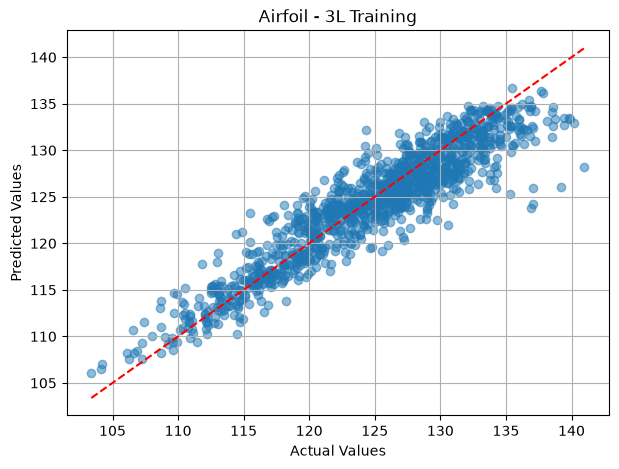

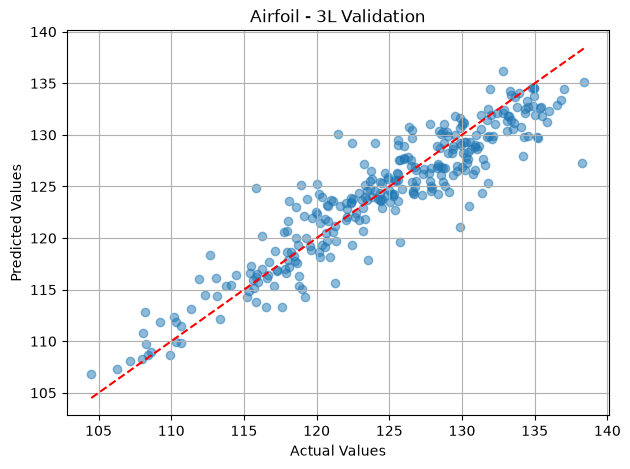

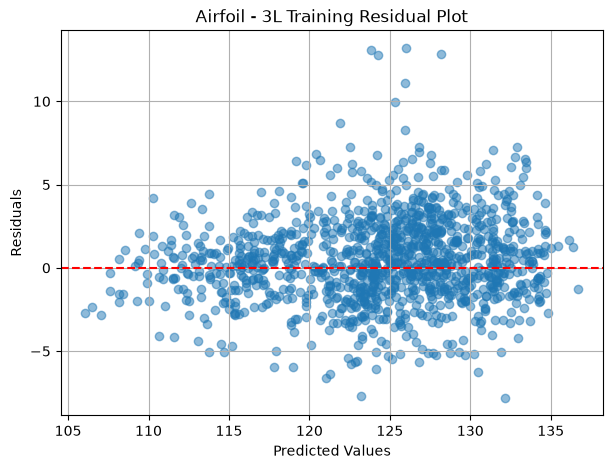

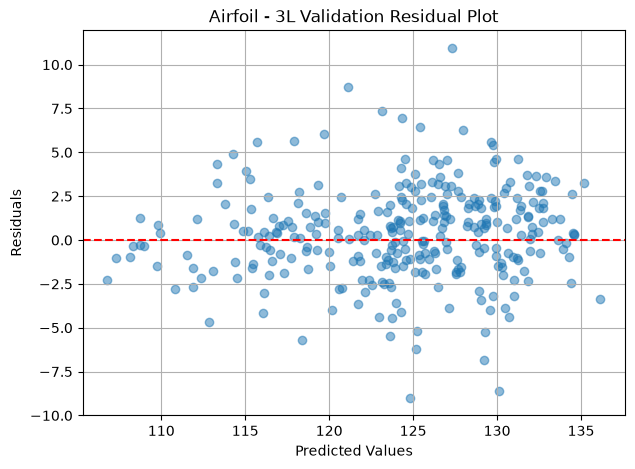

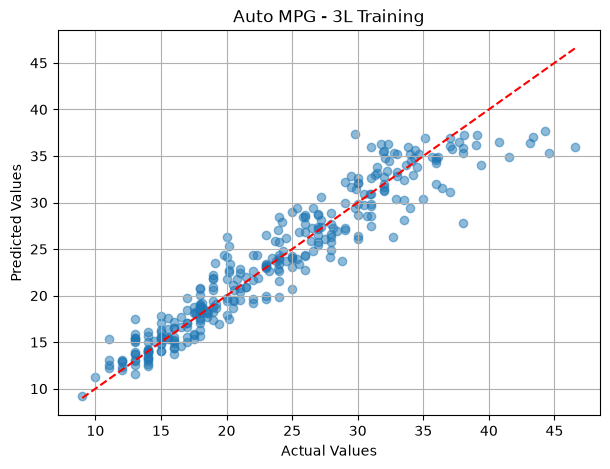

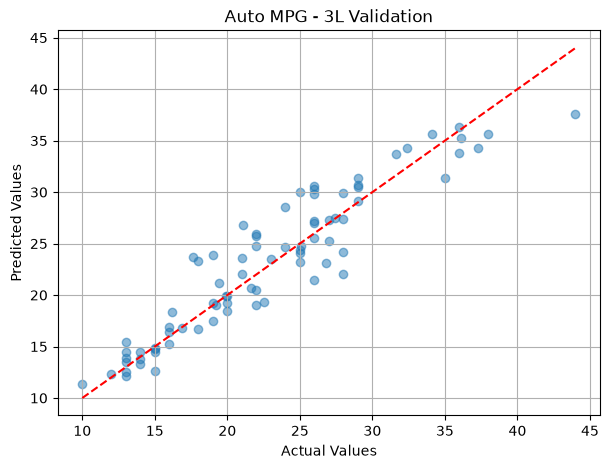

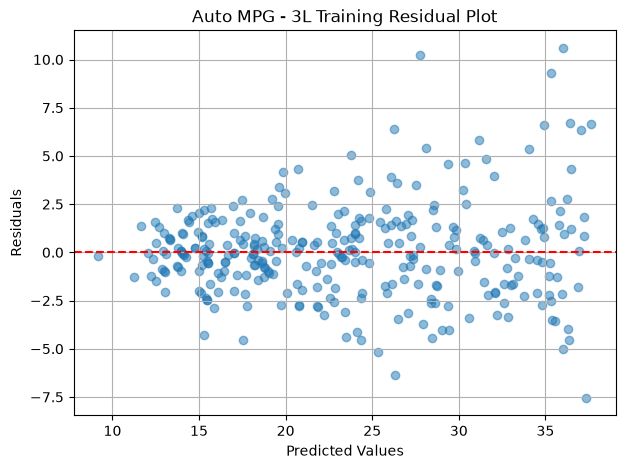

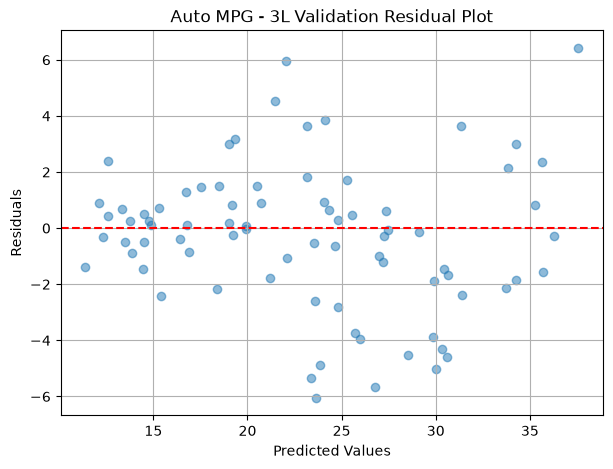

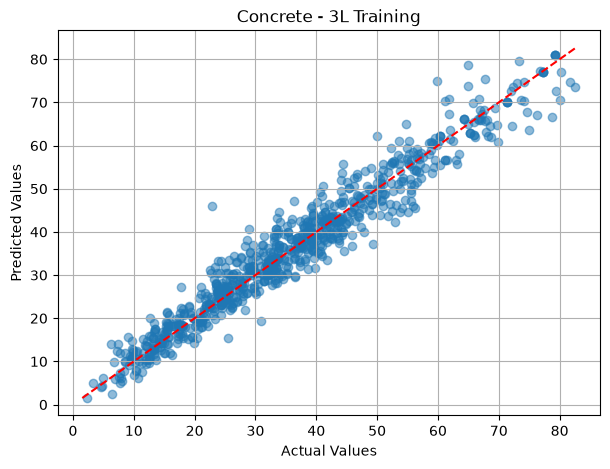

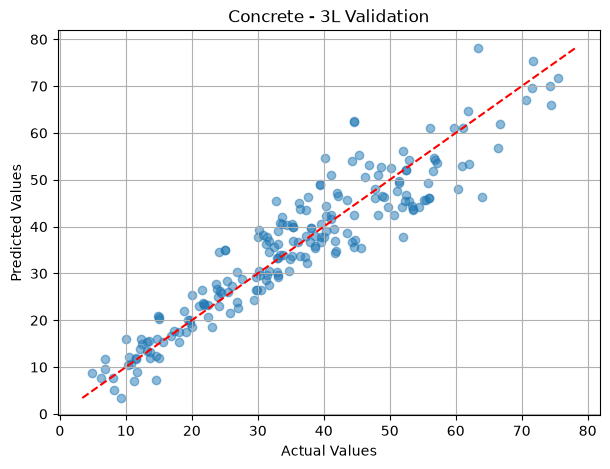

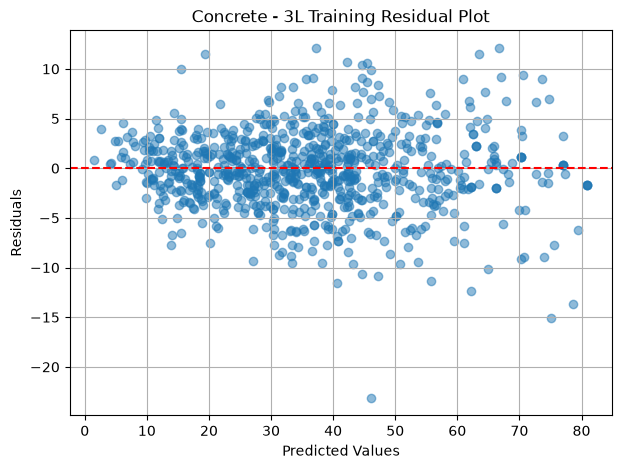

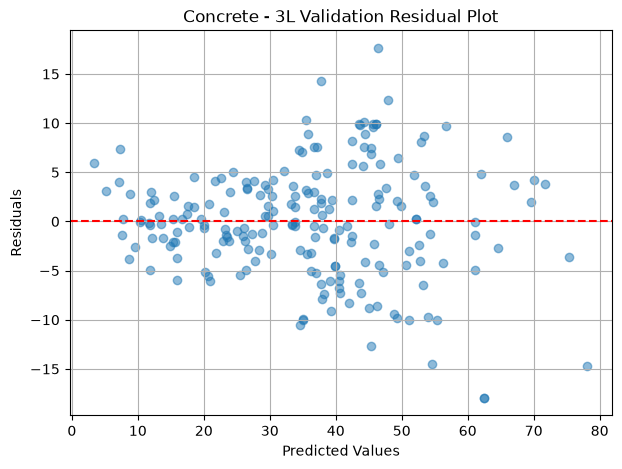

In [15]:
for name, model in models.items():
    X_train_t, y_train_t, X_test_t, y_test_t = tensors[name]
    plot_predictions(model, X_train_t, y_train_t, name, "Training")
    plot_predictions(model, X_test_t, y_test_t, name, "Validation")
    plot_residuals(model, X_train_t, y_train_t, name, "Training")
    plot_residuals(model, X_test_t, y_test_t, name, "Validation")